# Задание 2.4
## Множества точек на комплексной плоскости

### Условие:
Изобразите на комплексной плоскости множество точек, удовлетворяющих условию:

$$
\begin{aligned}
&a)\ |z-i|+|z+i|<4;\qquad b)\ \operatorname{Re}\bigl(z(1-i)\bigr)<\sqrt2;\qquad c)\ |z+1|=|z+i|=|z-i|;\\
&d)\ 0<\arg\frac{i-z}{z+i}<\frac\pi2;\qquad e)\ -\frac{2\pi}{3}\le\arg\frac{2-iz}{z+3i}\le-\frac{5\pi}{6};\qquad f)\ -\frac{2\pi}{3}\le\arg\frac{3-z}{z+i}\le-\frac\pi3.
\end{aligned}
$$

> **Замечание к пункту e).** Как записано в условии, неравенство $-\frac{2\pi}3\le\arg(\dots)\le-\frac{5\pi}6$ невыполнимо, потому что $-\frac{2\pi}{3}>-\frac{5\pi}{6}$ и множество пусто. Скорее всего, границы поменяны местами, поэтому решаем задачу $-\frac{5\pi}{6}\le\arg\frac{2-iz}{z+3i}\le-\frac{2\pi}{3}$.

### Решение (аналитически), $z=x+iy$

**a)** Это сумма расстояний до точек $\pm i$ (фокусы), $2a=4$, $c=1$, $b^2=a^2-c^2=3$. Множество — внутренность эллипса
$$\frac{x^2}{3}+\frac{y^2}{4}<1.$$

**b)** $z(1-i)=(x+iy)(1-i)=(x+y)+i(y-x)$, значит $\operatorname{Re}=x+y$. Условие: $x+y<\sqrt2$ — открытая полуплоскость под прямой $x+y=\sqrt2$.

**c)** Равенство $|z-i|=|z+i|$ даёт $y=0$. Равенство $|z+1|=|z+i|$: $(x+1)^2+y^2=x^2+(y+1)^2\Rightarrow x=y$. Итого $x=y=0$: единственная точка $z=0$ (центр окружности, проходящей через $-1,\ i,\ -i$; её радиус равен $1$).

**d)** Пусть $w=\dfrac{i-z}{z+i}$. Тогда
$$
w=\frac{(-x+i(1-y))\,(x-i(y+1))}{x^2+(y+1)^2}=\frac{(1-x^2-y^2)+2x\,i}{x^2+(y+1)^2}.
$$
Условие $0<\arg w<\frac\pi2$ означает $\operatorname{Re}w>0$ и $\operatorname{Im}w>0$, то есть $x^2+y^2<1$ и $x>0$. Это правая половина открытого единичного круга.

**e)** Вынесем множитель: $2-iz=-i(z+2i)$. Тогда $\dfrac{2-iz}{z+3i}=-i\cdot\dfrac{z+2i}{z+3i}$ и $\arg=-\dfrac\pi2+\theta$, $\theta=\arg\dfrac{z+2i}{z+3i}$ — угол, под которым из точки $z$ виден отрезок между $-3i$ и $-2i$ (с учётом направления). Условие $-\frac{5\pi}6\le-\frac\pi2+\theta\le-\frac{2\pi}3$ равносильно $-\frac\pi3\le\theta\le-\frac\pi6$. Отрицательный $\theta$ соответствует $x>0$ (проверка: $z=1$ даёт $\arg\frac{7-i}{10}<0$).
Хорда $AB$ ($A=-2i$, $B=-3i$) имеет длину $1$; геометрическое место точек, из которых она видна под углом $\alpha$, — дуга окружности радиуса $\dfrac{1}{2\sin\alpha}$:
$\alpha=\frac\pi3$: $R=\frac1{\sqrt3}$, центр $\bigl(\frac{1}{2\sqrt3},-\frac52\bigr)$; $\alpha=\frac\pi6$: $R=1$, центр $\bigl(\frac{\sqrt3}{2},-\frac52\bigr)$.
Угол между $\frac\pi6$ и $\frac\pi3$: точки правее мнимой оси, **внутри** большой окружности и **вне** малой (границы входят, точки $-2i$, $-3i$ не входят).

**f)** $\dfrac{3-z}{z+i}=-\dfrac{z-3}{z+i}$, поэтому условие равносильно $\varphi=\arg\dfrac{z-3}{z+i}\in\bigl[\frac\pi3,\frac{2\pi}3\bigr]$ ($\varphi>0$ — точки выше прямой через $-i$ и $3$, то есть $y>\frac x3-1$). Хорда $AB$ ($A=3$, $B=-i$) имеет длину $\sqrt{10}$. Углы $\frac\pi3$ и $\frac{2\pi}{3}$ дают две окружности одного радиуса $R=\dfrac{\sqrt{10}}{2\sin(\pi/3)}=\sqrt{\dfrac{10}{3}}$, симметричные относительно прямой $AB$. Центры: $M\pm\dfrac R2\,n$, где $M=\bigl(\frac32,-\frac12\bigr)$ — середина хорды, $n=\frac{(-1,3)}{\sqrt{10}}$. Искомое множество: часть выше прямой $AB$, **внутри** окружности с центром $M+\frac R2n$ и **вне** окружности с центром $M-\frac R2n$ (серповидная область, границы включены).

### Проверка и построение
На сетке точек вычислим условия **напрямую** (через `np.angle`, модули и т. д.), а затем сравним с аналитическими описаниями выше на случайных точках.

In [ ]:
import numpy as np

pi = np.pi
rng = np.random.default_rng(1)

def direct(name, z):
    # условие, записанное в точности как в задаче
    with np.errstate(all='ignore'):
        if name == 'a': return np.abs(z - 1j) + np.abs(z + 1j) < 4
        if name == 'b': return (z*(1 - 1j)).real < np.sqrt(2)
        if name == 'c': return np.isclose(abs(z + 1), abs(z + 1j)) & np.isclose(abs(z + 1j), abs(z - 1j))
        if name == 'd':
            a = np.angle((1j - z)/(z + 1j));  return (a > 0) & (a < pi/2)
        if name == 'e':
            a = np.angle((2 - 1j*z)/(z + 3j));  return (a >= -5*pi/6) & (a <= -2*pi/3)   # исправленный порядок границ
        if name == 'f':
            a = np.angle((3 - z)/(z + 1j));  return (a >= -2*pi/3) & (a <= -pi/3)

# окружности для e) и f)
c_big, R_big = 0.5*np.sqrt(3) - 2.5j, 1.0
c_small, R_small = 1/(2*np.sqrt(3)) - 2.5j, 1/np.sqrt(3)
Rf = np.sqrt(10/3)
M, nvec = 1.5 - 0.5j, (-1 + 3j)/np.sqrt(10)
C1, C2 = M + Rf/2*nvec, M - Rf/2*nvec

def analytic(name, z):
    x, y = z.real, z.imag
    if name == 'a': return x**2/3 + y**2/4 < 1
    if name == 'b': return x + y < np.sqrt(2)
    if name == 'd': return (x > 0) & (x**2 + y**2 < 1)
    if name == 'e': return (x > 0) & (abs(z - c_big) <= R_big) & (abs(z - c_small) >= R_small)
    if name == 'f': return (y > x/3 - 1) & (abs(z - C1) <= Rf) & (abs(z - C2) >= Rf)

pts = rng.uniform(-6, 6, 400000) + 1j*rng.uniform(-6, 6, 400000)
for name in 'abdef':
    d, a = direct(name, pts), analytic(name, pts)
    print(f'{name}) доля точек, где прямая проверка и формула расходятся: {np.mean(d != a):.5f}   (в области: {d.mean():.4f})')
print('c) z = 0 удовлетворяет условию:', bool(direct('c', np.array([0j]))[0]))
print('   точка 1+i условию не удовлетворяет:', not bool(direct('c', np.array([1+1j]))[0]))
print('e) как в условии (−2π/3 ≤ arg ≤ −5π/6): точек в множестве =',
      int(np.sum((np.angle((2 - 1j*pts)/(pts + 3j)) >= -2*pi/3) & (np.angle((2 - 1j*pts)/(pts + 3j)) <= -5*pi/6))))

a) доля точек, где прямая проверка и формула расходятся: 0.00000   (в области: 0.0751)
b) доля точек, где прямая проверка и формула расходятся: 0.00000   (в области: 0.6101)
d) доля точек, где прямая проверка и формула расходятся: 0.00000   (в области: 0.0109)
e) доля точек, где прямая проверка и формула расходятся: 0.00000   (в области: 0.0153)
f) доля точек, где прямая проверка и формула расходятся: 0.00000   (в области: 0.0437)
c) z = 0 удовлетворяет условию: True
   точка 1+i условию не удовлетворяет: True
e) как в условии (−2π/3 ≤ arg ≤ −5π/6): точек в множестве = 0


### Изображения

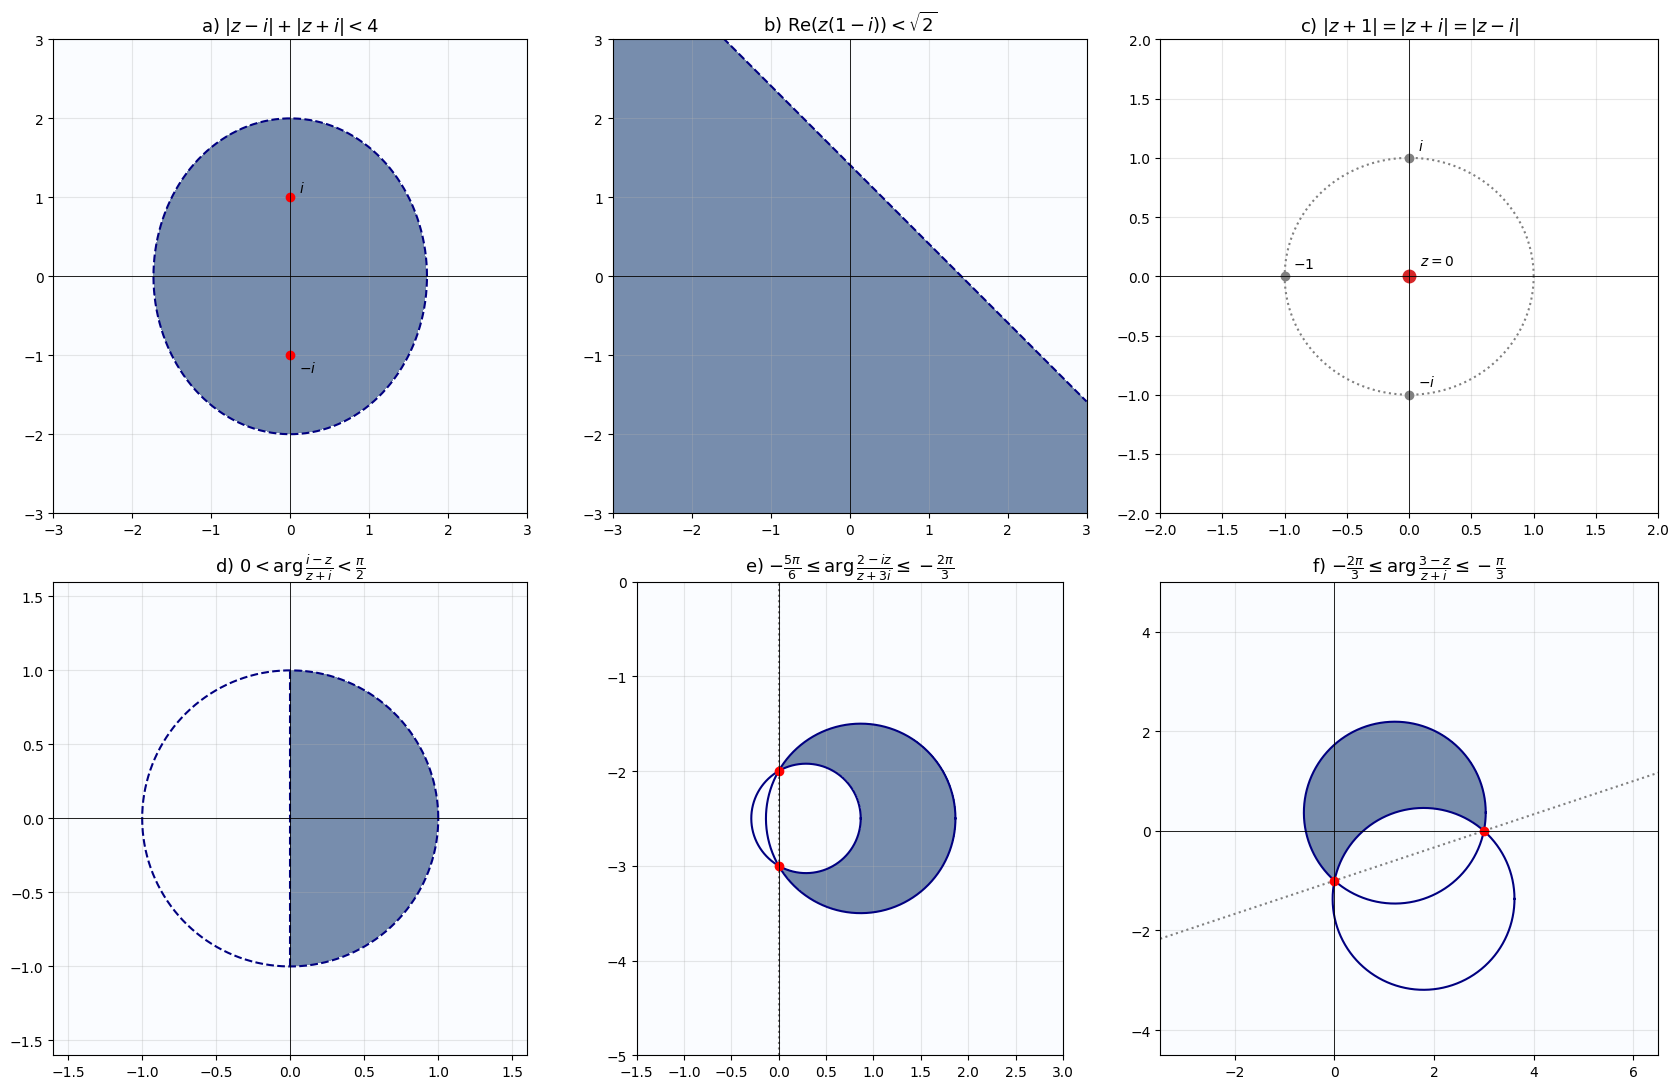

In [ ]:
import matplotlib.pyplot as plt

def grid(xmin, xmax, ymin, ymax, n=1400):
    xs, ys = np.linspace(xmin, xmax, n), np.linspace(ymin, ymax, n)
    X, Y = np.meshgrid(xs, ys)
    return X, Y, X + 1j*Y

t = np.linspace(0, 2*np.pi, 600)
def circ(ax, c, R, **kw): ax.plot(c.real + R*np.cos(t), c.imag + R*np.sin(t), **kw)

fig, axs = plt.subplots(2, 3, figsize=(17, 11))
boxes = {'a': (-3, 3, -3, 3), 'b': (-3, 3, -3, 3), 'c': (-2, 2, -2, 2),
         'd': (-1.6, 1.6, -1.6, 1.6), 'e': (-1.5, 3, -5, 0), 'f': (-3.5, 6.5, -4.5, 5)}
titles = {'a': r'a) $|z-i|+|z+i|<4$', 'b': r'b) $\mathrm{Re}(z(1-i))<\sqrt{2}$',
          'c': r'c) $|z+1|=|z+i|=|z-i|$', 'd': r'd) $0<\arg\frac{i-z}{z+i}<\frac{\pi}{2}$',
          'e': r'e) $-\frac{5\pi}{6}\leq\arg\frac{2-iz}{z+3i}\leq-\frac{2\pi}{3}$',
          'f': r'f) $-\frac{2\pi}{3}\leq\arg\frac{3-z}{z+i}\leq-\frac{\pi}{3}$'}

for ax, name in zip(axs.flat, 'abcdef'):
    x0, x1, y0, y1 = boxes[name]
    X, Y, Z = grid(x0, x1, y0, y1)
    if name != 'c':
        ax.imshow(direct(name, Z), extent=[x0, x1, y0, y1], origin='lower', cmap='Blues',
                  alpha=0.55, aspect='equal', interpolation='nearest')
    if name == 'a':
        ax.plot(np.sqrt(3)*np.cos(t), 2*np.sin(t), '--', color='navy')
        ax.plot([0, 0], [1, -1], 'ro'); ax.annotate('$i$', (0, 1), xytext=(6, 4), textcoords='offset points')
        ax.annotate('$-i$', (0, -1), xytext=(6, -12), textcoords='offset points')
    if name == 'b':
        xs = np.array([x0, x1]); ax.plot(xs, np.sqrt(2) - xs, '--', color='navy')
    if name == 'c':
        ax.plot(0, 0, 'o', color='tab:red', ms=9)
        for p, lab in [(-1, '$-1$'), (1j, '$i$'), (-1j, '$-i$')]:
            ax.plot(p.real, p.imag, 'o', color='gray'); ax.annotate(lab, (p.real, p.imag), xytext=(6, 6), textcoords='offset points')
        circ(ax, 0j, 1, ls=':', color='gray')
        ax.annotate('$z=0$', (0, 0), xytext=(8, 8), textcoords='offset points')
    if name == 'd':
        circ(ax, 0j, 1, ls='--', color='navy'); ax.plot([0, 0], [-1, 1], '--', color='navy')
    if name == 'e':
        circ(ax, c_big, R_big, color='navy'); circ(ax, c_small, R_small, color='navy')
        ax.plot([0, 0], [y0, y1], ':', color='gray'); ax.plot([0, 0], [-3, -2], 'ro')
    if name == 'f':
        circ(ax, C1, Rf, color='navy'); circ(ax, C2, Rf, color='navy')
        xs = np.array([x0, x1]); ax.plot(xs, xs/3 - 1, ':', color='gray'); ax.plot([0, 3], [-1, 0], 'ro')
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)
    ax.axhline(0, color='k', lw=0.6); ax.axvline(0, color='k', lw=0.6)
    ax.grid(alpha=0.3); ax.set_title(titles[name], fontsize=13)
plt.tight_layout()
plt.show()

### Ответ:

- **a)** внутренность эллипса $\dfrac{x^2}3+\dfrac{y^2}4<1$ (границы не входят);
- **b)** открытая полуплоскость $x+y<\sqrt2$;
- **c)** единственная точка $z=0$;
- **d)** правая половина открытого единичного круга: $x>0,\ x^2+y^2<1$;
- **e)** (при исправленном порядке границ) область правее мнимой оси между двумя дугами окружностей: внутри круга радиуса $1$ с центром $\frac{\sqrt3}2-\frac52i$ и вне круга радиуса $\frac1{\sqrt3}$ с центром $\frac1{2\sqrt3}-\frac52i$, границы включены, точки $-2i$ и $-3i$ исключены. В исходной записи множество пусто;
- **f)** серповидная область выше прямой $y=\frac x3-1$ внутри круга радиуса $\sqrt{10/3}$ с центром $M+\frac R2n$ и вне круга того же радиуса с центром $M-\frac R2n$ ($M=\frac32-\frac i2$, $n=\frac{-1+3i}{\sqrt{10}}$), границы включены, точки $-i$ и $3$ исключены.